In [5]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from src import monte_carlo as mc
from src import black_scholes as bs
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# benchmark parameters
S = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

#initial montecarlo_parameters
n = 100000
h = 0.1

In [3]:
# benchmark bs calcs
benchmark_call_price = bs.black_scholes_price(S, K, T, r, sigma, "call")
benchmark_put_price = bs.black_scholes_price(S, K, T, r, sigma, "put")

print(benchmark_call_price,benchmark_put_price)

benchmark_delta_call = bs.option_delta(S, K, T, r, sigma, "call")
benchmark_delta_put = bs.option_delta(S, K, T, r, sigma, "put")

benchmark_gamma = bs.option_gamma(S,K,T,r,sigma)

benchmark_vega = bs.option_vega(S, K, T, r, sigma)

benchmark_theta_call = bs.option_theta(S, K, T, r, sigma, "call")
benchmark_theta_put = bs.option_theta(S, K, T, r, sigma, "put")

benchmark_rho_call = bs.option_rho(S, K, T, r, sigma, "call")
benchmark_rho_put = bs.option_rho(S, K, T, r, sigma, "put")

print(benchmark_delta_call, benchmark_delta_put, benchmark_gamma, benchmark_vega, benchmark_theta_call,
      benchmark_theta_put, benchmark_rho_call, benchmark_rho_put)


10.450583572185565 5.573526022256971
0.6368306511756191 -0.3631693488243809 0.018762017345846895 37.52403469169379 -6.414027546438197 -1.657880423934626 53.232481545376345 -41.89046090469506


In [ ]:
# monte carlo greeks calculations
mc_delta = mc.monte_carlo_delta(S, K, T, r, sigma, n, "call", h)
mc_gamma = mc.monte_carlo_gamma(S, K, T, r, sigma, n, "call", h)
mc_vega = mc.monte_carlo_vega(S, K, T, r, sigma, n, "call", h)
mc_rho = mc.monte_carlo_rho(S, K, T, r, sigma, n, "call", h)
mc_theta = mc.monte_carlo_theta(S, K, T, r, sigma, n, "call", h)

print("Delta:", mc_delta)
print("Gamma:", mc_gamma)
print("Vega:", mc_vega)
print("Rho:", mc_rho)
print("Theta:", mc_theta)

Delta: 0.6345226137325977
Gamma: 0.019709278744350908
Vega: 37.291417583717106
Rho: 52.2368143701429
Theta: 6.375063722233936


In [ ]:
#absolute and relative error comparison to bs benchmarks
import pandas as pd

greek_comparison = pd.DataFrame({
    "Greek": ["Delta", "Gamma", "Vega", "Rho", "Theta"],
    "Monte Carlo": [
        mc_delta,
        mc_gamma,
        mc_vega,
        mc_rho,
        mc_theta
    ],
    "Black-Scholes": [
        benchmark_delta_call,
        benchmark_gamma,
        benchmark_vega,
        benchmark_rho_call,
        benchmark_theta_call
    ]
})

greek_comparison["Absolute Error"] = abs(
    greek_comparison["Monte Carlo"] - greek_comparison["Black-Scholes"])

greek_comparison["Relative Error (%)"] = (
    greek_comparison["Absolute Error"] /abs(greek_comparison["Black-Scholes"])*100)

greek_comparison

,Greek,Monte Carlo,Black-Scholes,Absolute Error,Relative Error (%)
0,Delta,0.634523,0.636831,0.002308,0.362426
1,Gamma,0.019709,0.018762,0.000947,5.048825
2,Vega,37.291418,37.524035,0.232617,0.619915
3,Rho,52.236814,53.232482,0.995667,1.870413
4,Theta,6.375064,6.414028,0.038964,0.607478


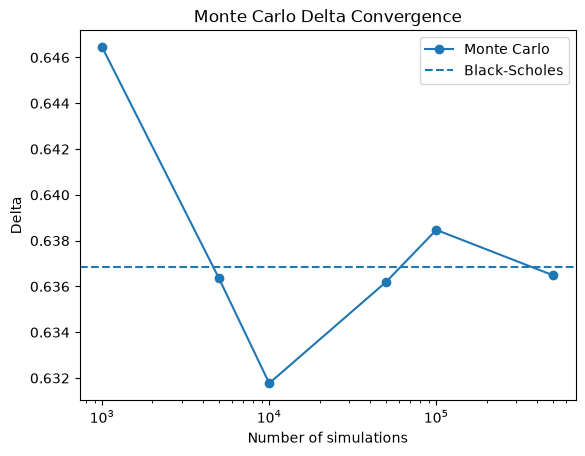

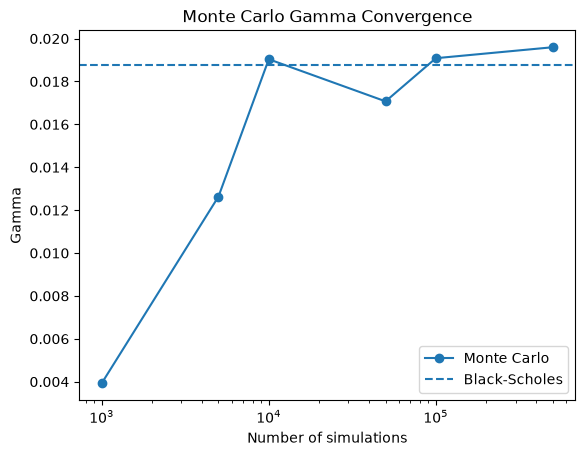

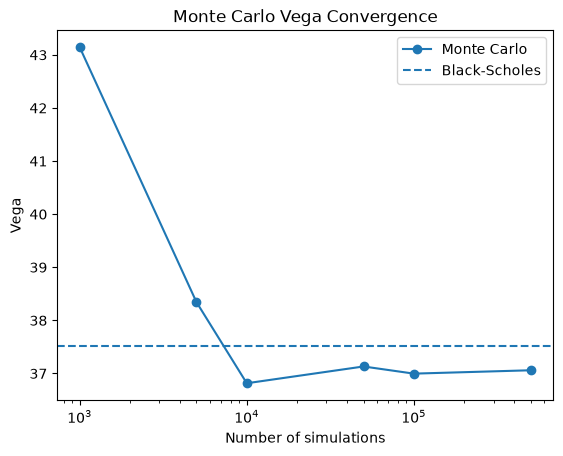

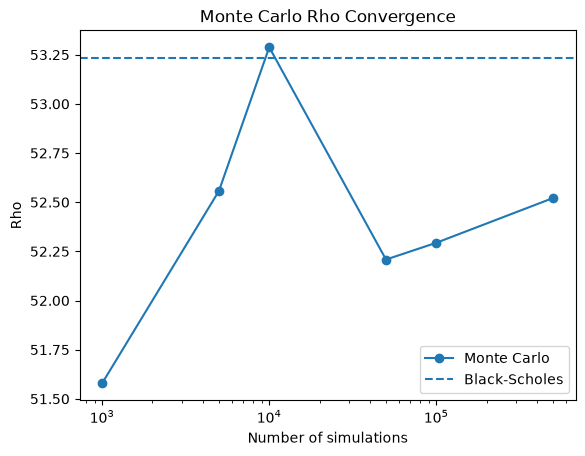

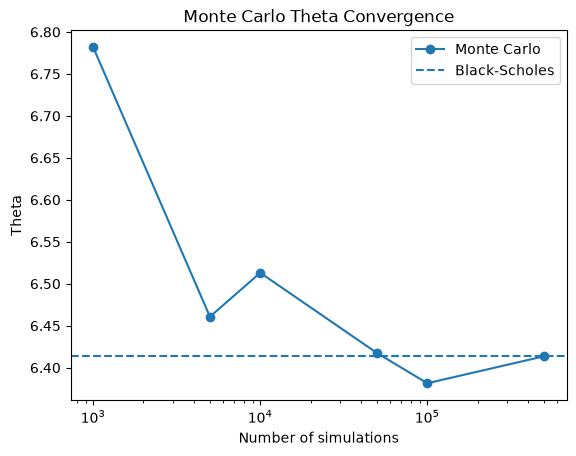

In [ ]:
# convergence analysis
simulation_counts = [1000, 5000, 10000, 50000, 100000, 500000]

delta_values = []
gamma_values = []
vega_values = []
rho_values = []
theta_values = []

for N in simulation_counts:

    delta_values.append(mc.monte_carlo_delta(S, K, T, r, sigma, N, "call", h))
    gamma_values.append(mc.monte_carlo_gamma(S, K, T, r, sigma, N, "call", h))
    vega_values.append(mc.monte_carlo_vega(S, K, T, r, sigma, N, "call", h))
    rho_values.append(mc.monte_carlo_rho(S, K, T, r, sigma, N, "call", h))
    theta_values.append(mc.monte_carlo_theta(S, K, T, r, sigma, N, "call", h))

# now we plot the data, different axes for the different greeks given different scales

plt.plot(simulation_counts, delta_values, marker="o", label="Monte Carlo")
plt.axhline(benchmark_delta_call, linestyle="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Delta")
plt.title("Monte Carlo Delta Convergence")
plt.legend()
plt.show()

plt.plot(simulation_counts, gamma_values, marker="o", label="Monte Carlo")
plt.axhline(benchmark_gamma, linestyle="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Gamma")
plt.title("Monte Carlo Gamma Convergence")
plt.legend()
plt.show()

plt.plot(simulation_counts, vega_values, marker="o", label="Monte Carlo")
plt.axhline(benchmark_vega, linestyle="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Vega")
plt.title("Monte Carlo Vega Convergence")
plt.legend()
plt.show()

plt.plot(simulation_counts, rho_values, marker="o", label="Monte Carlo")
plt.axhline(benchmark_rho_call, linestyle="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Rho")
plt.title("Monte Carlo Rho Convergence")
plt.legend()
plt.show()

plt.plot(simulation_counts, theta_values, marker="o", label="Monte Carlo")
plt.axhline(benchmark_theta_call, linestyle="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Theta")
plt.title("Monte Carlo Theta Convergence")
plt.legend()
plt.show()

In [ ]:
# Calculate absolute errors for each Greek at each simulation count

delta_errors = np.abs(np.array(delta_values) - benchmark_delta_call)
gamma_errors = np.abs(np.array(gamma_values) - benchmark_gamma)
vega_errors = np.abs(np.array(vega_values) - benchmark_vega)
rho_errors = np.abs(np.array(rho_values) - benchmark_rho_call)
# MC theta now returns dV/dt (sign fixed in monte_carlo.py), matching BS theta directly
theta_errors = np.abs(np.array(theta_values) - benchmark_theta_call)

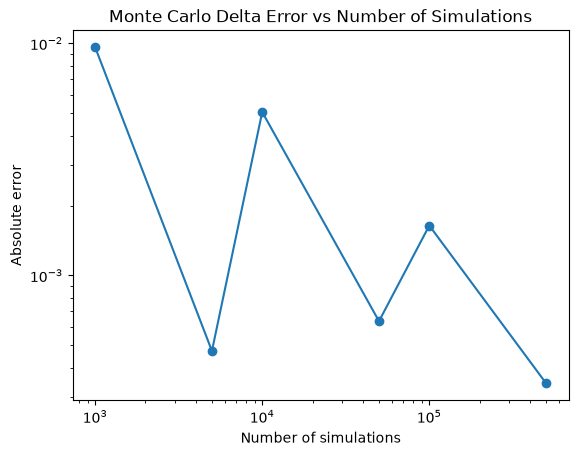

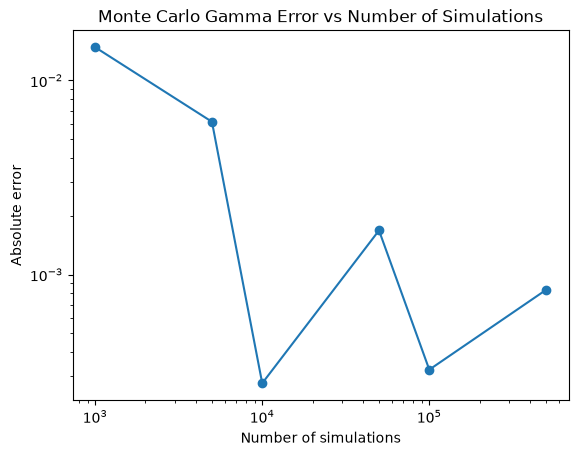

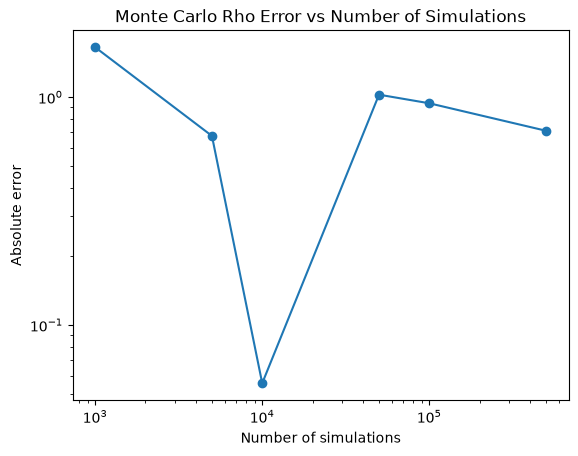

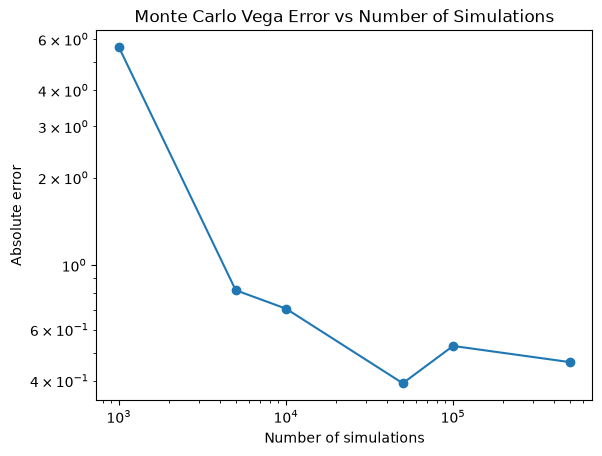

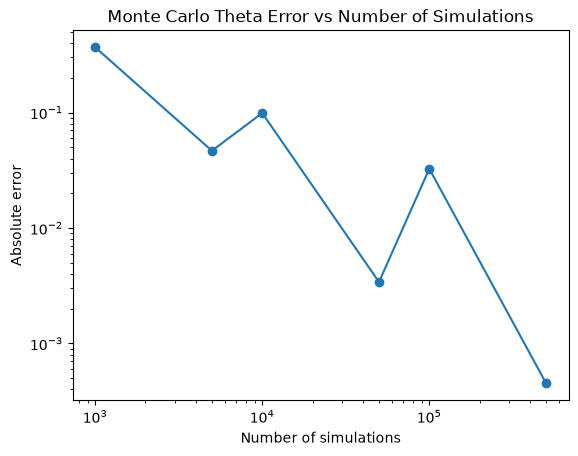

In [17]:
# plots we begin with delta
plt.plot(simulation_counts, delta_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Absolute error")
plt.title("Monte Carlo Delta Error vs Number of Simulations")
plt.show()

#then gamma
plt.plot(simulation_counts, gamma_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Absolute error")
plt.title("Monte Carlo Gamma Error vs Number of Simulations")
plt.show()

#then rho
plt.plot(simulation_counts, rho_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Absolute error")
plt.title("Monte Carlo Rho Error vs Number of Simulations")
plt.show()

#then vega
plt.plot(simulation_counts, vega_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Absolute error")
plt.title("Monte Carlo Vega Error vs Number of Simulations")
plt.show()

#then theta
plt.plot(simulation_counts, theta_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Absolute error")
plt.title("Monte Carlo Theta Error vs Number of Simulations")
plt.show()



In [ ]:
# behaviour as stepsize h changes analysis
# we need to use different h for the different greeks, given their raw volatility
# varies by orders of magnitude, using the same h array would result in huge swings for 
# more sensitive greeks

# Fixed number of simulations
n = 100000

# Step sizes for each finite-difference Greek
delta_gamma_h = [2, 1, 0.5, 0.2, 0.1, 0.05, 0.02]
vega_h = [0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001]
rho_h = [0.05, 0.02, 0.01, 0.005, 0.002, 0.001, 0.0005]
theta_h = [0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001]

# Calculate Delta errors
delta_h_values = []
delta_h_errors = []
for h_value in delta_gamma_h:
    delta = mc.monte_carlo_delta(S, K, T, r, sigma, n, "call", h_value)
    error = abs(delta - benchmark_delta_call)
    delta_h_values.append(delta)
    delta_h_errors.append(error)

# Calculate Gamma errors
gamma_h_values = []
gamma_h_errors = []
for h_value in delta_gamma_h:
    gamma = mc.monte_carlo_gamma(S, K, T, r, sigma, n, "call", h_value) 
    error = abs(gamma - benchmark_gamma)
    gamma_h_values.append(gamma)
    gamma_h_errors.append(error)

# Calculate Vega errors
vega_h_values = []
vega_h_errors = []
for h_value in vega_h: 
    vega = mc.monte_carlo_vega(S, K, T, r, sigma, n, "call", h_value)
    error = abs(vega - benchmark_vega)
    vega_h_values.append(vega)
    vega_h_errors.append(error)

# Calculate Rho errors
rho_h_values = []
rho_h_errors = []
for h_value in rho_h:
    rho = mc.monte_carlo_rho(S, K, T, r, sigma, n, "call", h_value)
    error = abs(rho - benchmark_rho_call)
    rho_h_values.append(rho)
    rho_h_errors.append(error)

# Calculate Theta errors
theta_h_values = []
theta_h_errors = []
for h_value in theta_h:
    theta = mc.monte_carlo_theta(S, K, T, r, sigma, n, "call", h_value)
    # MC Theta is negantive, this is fixed in the mc code so no sign correction needed here
    error = abs(theta - benchmark_theta_call)
    theta_h_values.append(theta)
    theta_h_errors.append(error)


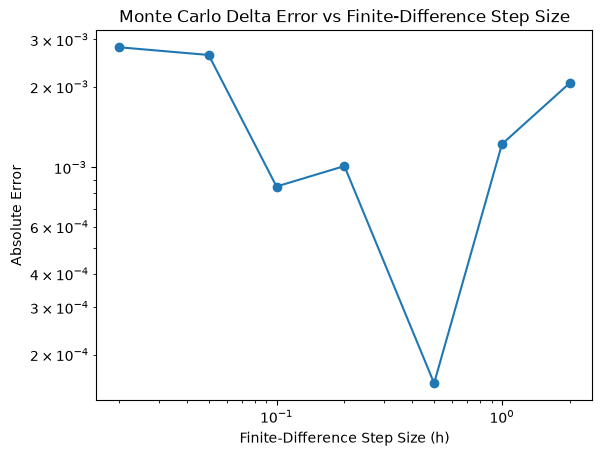

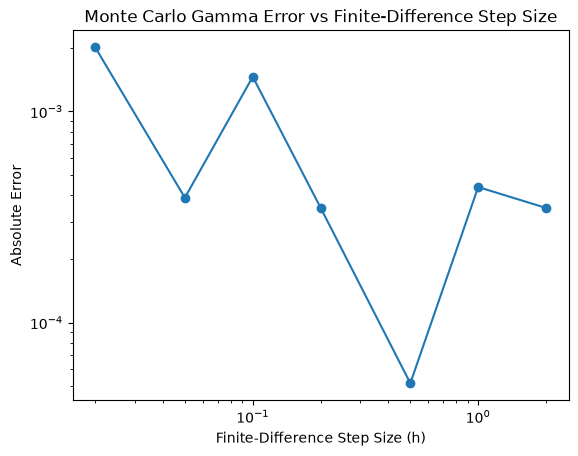

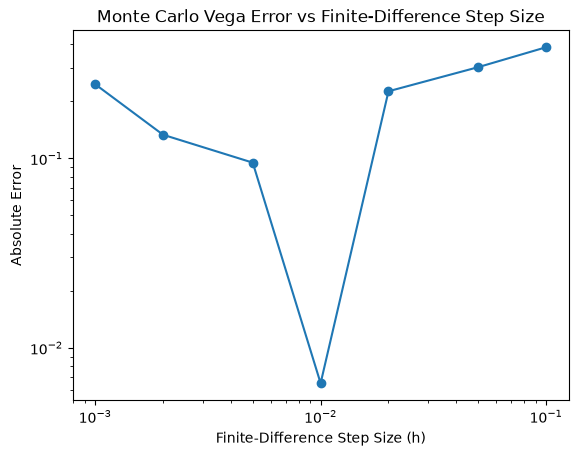

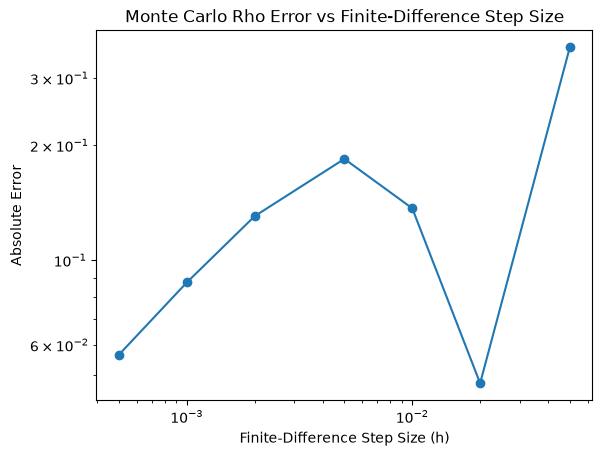

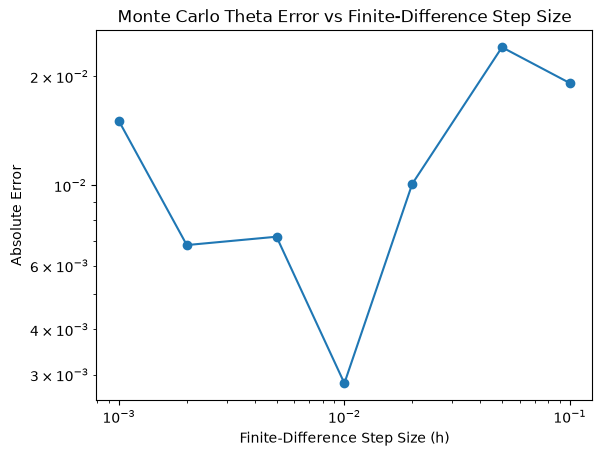

: 

In [ ]:
# now we plot this info

# delta plotting
plt.plot(delta_gamma_h, delta_h_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Finite-Difference Step Size (h)")
plt.ylabel("Absolute Error")
plt.title("Monte Carlo Delta Error vs Finite-Difference Step Size")
plt.show()

#gamma plot
plt.plot(delta_gamma_h, gamma_h_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Finite-Difference Step Size (h)")
plt.ylabel("Absolute Error")
plt.title("Monte Carlo Gamma Error vs Finite-Difference Step Size")
plt.show()

#vega plot
plt.plot(vega_h, vega_h_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Finite-Difference Step Size (h)")
plt.ylabel("Absolute Error")
plt.title("Monte Carlo Vega Error vs Finite-Difference Step Size")
plt.show()

#rho plot
plt.plot(rho_h, rho_h_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Finite-Difference Step Size (h)")
plt.ylabel("Absolute Error")
plt.title("Monte Carlo Rho Error vs Finite-Difference Step Size")
plt.show()

#theta plot
plt.plot(theta_h, theta_h_errors, marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Finite-Difference Step Size (h)")
plt.ylabel("Absolute Error")
plt.title("Monte Carlo Theta Error vs Finite-Difference Step Size")
plt.show()

In [ ]:
#delta, gamma and vega across spot and maturity
spots = np.linspace(70, 130, 300)
maturities = [0.05, 0.25, 1.0]
K_g, r_g, sigma_g = 100, 0.05, 0.20

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for T_g in maturities:
    axes[0].plot(spots, bs.option_delta(spots, K_g, T_g, r_g, sigma_g, "call"), label=f"T = {T_g}")
    axes[1].plot(spots, bs.option_gamma(spots, K_g, T_g, r_g, sigma_g), label=f"T = {T_g}")
    axes[2].plot(spots, bs.option_vega(spots, K_g, T_g, r_g, sigma_g) / 100, label=f"T = {T_g}")

for ax, title, ylabel in zip(
    axes,
    ["Delta (call)", "Gamma", "Vega"],
    ["Delta", "Gamma", "Price change per 1 vol point"],
):
    ax.axvline(K_g, color="grey", linestyle="--", linewidth=1)
    ax.set_xlabel("Spot price")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
#hedging risk
S0, K_g, T_g, r_g, sigma_g = 100, 100, 0.25, 0.05, 0.20

c0 = bs.black_scholes_price(S0, K_g, T_g, r_g, sigma_g, "call")
delta0 = bs.option_delta(S0, K_g, T_g, r_g, sigma_g, "call")
gamma0 = bs.option_gamma(S0, K_g, T_g, r_g, sigma_g)
vega0 = bs.option_vega(S0, K_g, T_g, r_g, sigma_g)

# gamma risk: P&L of a delta-hedged long call after an instant spot move
dS = np.linspace(-15, 15, 200)
repriced = bs.black_scholes_price(S0 + dS, K_g, T_g, r_g, sigma_g, "call")
hedged_pnl = repriced - c0 - delta0 * dS
gamma_approx = 0.5 * gamma0 * dS**2

# vega risk: P&L of the same call after a volatility shift
dvol = np.linspace(-0.10, 0.10, 200)
repriced_vol = bs.black_scholes_price(S0, K_g, T_g, r_g, sigma_g + dvol, "call")
vol_pnl = repriced_vol - c0
vega_approx = vega0 * dvol

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(dS, hedged_pnl, label="Exact residual P&L after delta hedge")
axes[0].plot(dS, gamma_approx, linestyle="--", label="Gamma approximation: 0.5 * Gamma * dS^2")
axes[0].set_xlabel("Spot move (dS)")
axes[0].set_ylabel("P&L")
axes[0].set_title("Gamma risk: what a delta hedge does not cover")
axes[0].legend()

axes[1].plot(dvol * 100, vol_pnl, label="Exact P&L")
axes[1].plot(dvol * 100, vega_approx, linestyle="--", label="Vega approximation: Vega * d(sigma)")
axes[1].set_xlabel("Volatility shift (vol points)")
axes[1].set_ylabel("P&L")
axes[1].set_title("Vega risk: exposure to volatility moves")
axes[1].legend()

plt.tight_layout()
plt.show()